# Part E: One page of written justification (15 marks)

The numbers below come from code. The reasoning in the written cells is mine.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from vizlib import PALETTE, style_defaults, save_fig   # Week 3 toolkit
import tslib                                           # Week 4 toolkit

%matplotlib inline
style_defaults()

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

def save(fig, name, note=None):
    """fig.savefig first (300 dpi, tight), THEN the figure is shown."""
    save_fig(fig, FIG / name, note)

def check(label, ok, detail=""):
    print(f"[{'PASS' if ok else 'FAIL'}] {label} {detail}")

In [2]:
def load_clean():
    """Same cleaning as Part D (step-by-step version is in part_d.ipynb)."""
    log = []
    df = pd.read_csv(DATA / "sessions_hourly.csv")
    iso = df.ts.str.contains("-")                      # ISO rows vs dd/mm/yyyy rows
    t = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")
    t[iso] = pd.to_datetime(df.ts[iso], format="%Y-%m-%d %H:%M:%S")
    t[~iso] = pd.to_datetime(df.ts[~iso], format="%d/%m/%Y %H:%M")
    log.append(("parse slash rows as dd/mm/yyyy", int((~iso).sum())))
    df["t"] = t
    df = df.drop(columns="ts")
    log.append(("device case normalised", int((df.device != df.device.str.strip().str.title()).sum())))
    df["device"] = df.device.str.strip().str.title()
    n = len(df); df = df.drop_duplicates(); log.append(("exact duplicate rows dropped", n - len(df)))
    df = df.set_index("t").sort_index()
    log.append(("sessions == -1 sentinel -> NaN", int((df.sessions == -1).sum())))
    df["sessions"] = df.sessions.where(df.sessions != -1)
    full = pd.date_range(df.index.min(), df.index.max(), freq="h")
    log.append(("hours never recorded (reindexed)", len(full) - len(df)))
    hourly = df.reindex(full); hourly.index.name = "t"
    daily = hourly.sessions.resample("D").sum(min_count=1)   # sessions is a flow: sum
    log.append(("whole days with no data (NaN)", int(daily.isna().sum())))
    return hourly, daily, log

hourly, daily, log = load_clean()
raw_cat = pd.read_csv(DATA / "revenue_catalogue.csv")
cat = raw_cat.drop_duplicates("sku")
neg = cat[cat.net_revenue_pkr_m < 0]; pos = cat[cat.net_revenue_pkr_m >= 0]
sub = pos.groupby(["category", "subcategory"], as_index=False).net_revenue_pkr_m.sum()
sub["share_pct"] = sub.net_revenue_pkr_m / sub.net_revenue_pkr_m.sum() * 100
WINDOW = 7
smooth = daily.rolling(WINDOW, center=True, min_periods=WINDOW // 2 + 1).mean().dropna()
w, h = tslib.banked_figsize(smooth.to_numpy())
print(f"banked_figsize: {w:.1f} x {h:.1f} in (aspect {h/w:.2f})")
print("index audit (hourly):", tslib.audit_index(hourly.dropna(subset=["orders"]), "h"))
pd.DataFrame(log, columns=["rule", "rows"])

banked_figsize: 9.0 x 3.9 in (aspect 0.43)
index audit (hourly): {'dtype_ok': True, 'monotonic': True, 'n_rows': 12384, 'n_duplicated': 0, 'n_missing': 312, 'missing_dates': ['2024-05-18 00:00:00', '2024-05-18 01:00:00', '2024-05-18 02:00:00', '2024-05-18 03:00:00', '2024-05-18 04:00:00', '2024-05-18 05:00:00', '2024-05-18 06:00:00', '2024-05-18 07:00:00', '2024-05-18 08:00:00', '2024-05-18 09:00:00', '2024-05-18 10:00:00', '2024-05-18 11:00:00'], 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00'), 'partial_tail': False, 'tail_period': '2025-09-11', 'tail_count': 24}


,rule,rows
0,parse slash rows as dd/mm/yyyy,3651
1,device case normalised,1447
2,exact duplicate rows dropped,286
3,sessions == -1 sentinel -> NaN,287
4,hours never recorded (reindexed),312
5,whole days with no data (NaN),13


In [3]:
print(f"{len(raw_cat)} catalogue rows ({cat.sku.nunique()} unique SKUs) rolled up to {len(sub)} sub-categories under {sub.category.nunique()} categories")
print(f"smallest sub-category: {sub.subcategory[sub.share_pct.idxmin()]} at {sub.share_pct.min():.1f}% -> no 'Other' bucket needed")
print(f"negative-net rows excluded from area: {len(neg)}, worth {neg.net_revenue_pkr_m.sum():.3f}m")

345 catalogue rows (344 unique SKUs) rolled up to 8 sub-categories under 4 categories
smallest sub-category: Drones at 2.4% -> no 'Other' bucket needed
negative-net rows excluded from area: 7, worth -1.069m


## 1. Per panel: question, chart type, Week 2 channel rule (4 marks)
- **Panel 1 (daily series):** *Is traffic growing, and is anything unusual?* A line: **position on a common scale**, the most accurate channel. Raw days in light grey, the named 7-day mean in one saturated colour on top.
- **Panel 2 (heatmap):** *When in the week and day do people visit?* Both axes are cyclic categories (7 × 24), so a heatmap. Value = **lightness of one sequential hue** (Blues, no rainbow), a weak channel, so the colourbar carries units.
- **Panel 3 (treemap):** *Where is the revenue mass?* **Area** is the fourth-best channel (about ±20%), so every value is printed. **Hue = parent category**; the 4th hue (pink) is weak on contrast, so blocks are also labelled.
- **Panel 4 (sorted bars):** *By how much do the eight differ?* **Length from a common zero**, sorted, values printed, same hue per parent as panel 3. Treemap = where, bars = by how much.

## 2. Every time decision, named and defended (5 marks)
- **Parse:** `ts` has two formats, ISO (9,019 rows) and `dd/mm/yyyy` (3,651). A default parse gives 3,651 NaT; `format="mixed"` parses all but reads them month-first and spans 2024-01-04 to 2025-12-08 instead of 2024-04-01 to 2025-09-11. Day-first is proven by the data: 2,151 slash rows have a first field above 12, none a second. Each format has an explicit format string.
- **Resolution:** hourly for the heatmap (hour of day is the question); **daily** for the trend, since the cycle to remove is weekly.
- **Aggregation:** `sessions` is a flow, so daily = **sum** with `min_count=1` (13 unrecorded days stay NaN, not 0); the heatmap uses the **mean** per cell, a rate. Gaps were counted on the hourly index (312 hours = 13 days) before resampling.
- **Window:** **7 days**, to cancel the weekly cycle (peak-to-trough 7,352 sessions a day), not for smoothness (Part B.1).
- **Centred, not trailing:** this is a retrospective figure, and a trailing mean would show every turn **3 days late** (half the window, Part B.4). A live Monday dashboard should use trailing, captioned "7-day trailing mean: turns appear about 3 days late".

**Ethics clause (be honest):** The window was fixed at **7 days** before plotting because the cycle being removed is weekly (Part B.1). The series is shown from **its first recorded day (1 Apr 2024) to its last**; no start date was **selected**. A **28-day version is in the appendix and does not change the direction** (both rise +20.6 sessions per day per day). Part B.5 shows the start month decides the sign (37 of 60 combinations rise, 23 fall), which is why the start was not left to me. Symmetry test: **I would have made the same choice if it had weakened my conclusion**, because the window comes from the weekly cycle and the start from the file's first row. *(I must confirm this is true of my own process before submitting.)*

## 3. Every row removed (3 marks)
Sessions (12,670 rows): **3,651** slash rows re-parsed, not removed (NaT 3,651 → 0); **1,447** device labels normalised (strip + title case, 6 spellings → 3); **286** exact duplicates dropped (12,670 → 12,384); **287** `-1` sentinels set to NaN, never 0 (min −1 → 179), which understates the total by about 2% (≈ 287 h × 970 ≈ 278k of 11.7m); **312** unrecorded hours reindexed as NaN (12,384 → 12,696 slots), leaving **13** empty days. Black Friday (113,710) was kept: it is a real event.
Catalogue (345 rows): **1** duplicate SKU (SKU-0127) dropped (345 → 344), without which the worst share is 0.94 points off `shares_eight.csv`, with it 0.23; **7** negative-net rows (−1.069m) kept out of area (1,711.38m → 1,712.45m positive).

## 4. Every level rolled up (3 marks)
There is **no `Other`**: at a 1% threshold nothing folds, as the smallest sub-category (Drones, 41.3m) is 2.4%. The 344 SKUs roll up to **8 sub-categories in 4 categories**, and I cut the depth there on purpose: at SKU level 311 of 337 SKUs fall below 1% and would form an `Other` of 426.5m, **24.9% of revenue** hidden in one block.

## Appendix: the 28-day version
Same series, same start, same end, window 28 instead of 7. The direction does not change.

7-day: slope +20.6 sessions/day per day, 13,670 -> 26,927
28-day: slope +20.6 sessions/day per day, 15,170 -> 29,743


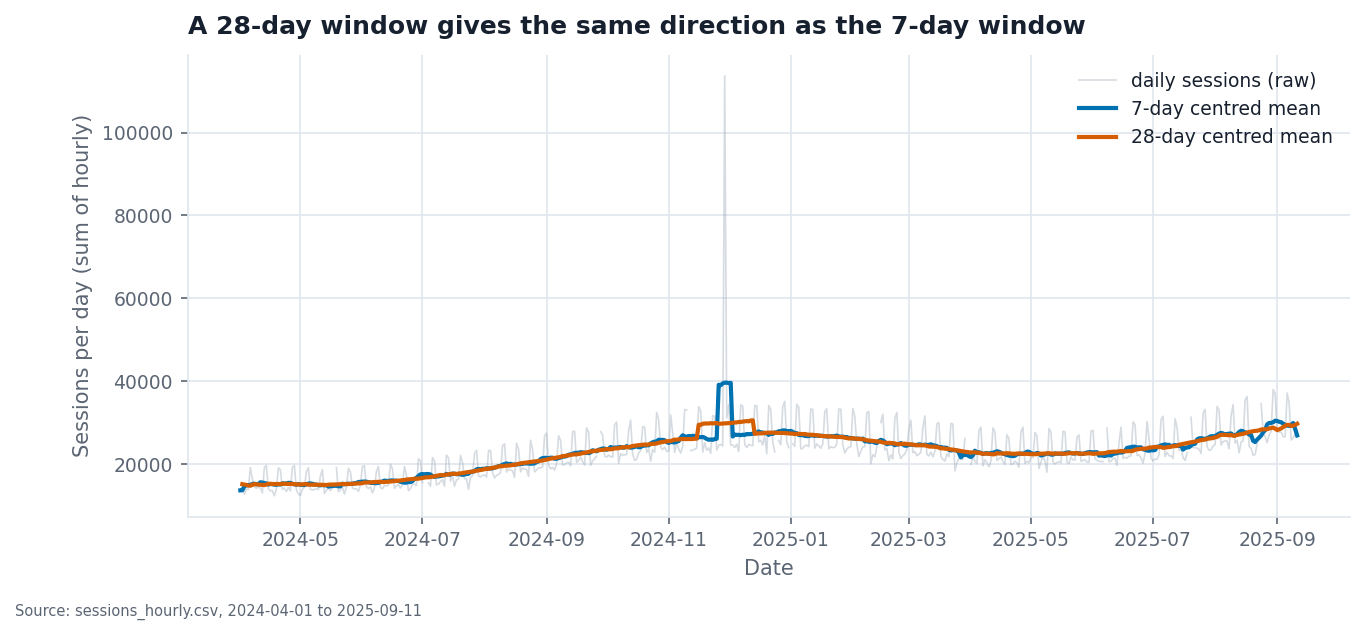

In [4]:
w28 = daily.rolling(28, center=True, min_periods=15).mean().dropna()
sm7 = daily.rolling(7, center=True, min_periods=4).mean().dropna()
for nm, s_ in (("7-day", sm7), ("28-day", w28)):
    print(f"{nm}: slope {np.polyfit(np.arange(len(s_)), s_.to_numpy(), 1)[0]:+.1f} sessions/day per day, {s_.iloc[0]:,.0f} -> {s_.iloc[-1]:,.0f}")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily, color=PALETTE["muted"], alpha=0.4, linewidth=0.8, label="daily sessions (raw)")
ax.plot(sm7.index, sm7, color=PALETTE["series"][0], label="7-day centred mean")
ax.plot(w28.index, w28, color=PALETTE["series"][1], label="28-day centred mean")
ax.set_title("A 28-day window gives the same direction as the 7-day window")
ax.set_xlabel("Date"); ax.set_ylabel("Sessions per day (sum of hourly)"); ax.legend()
save(fig, "part_e_appendix_28d.png", "Source: sessions_hourly.csv, 2024-04-01 to 2025-09-11")
plt.show()